# Level 1 — Task 4: Online Delivery

### Online Delivery Availability & Its Link with Ratings

This dataset contains 9,551 restaurant listings scraped from a Zomato-style
platform, covering cuisine type, cost, ratings, and location across multiple
cities and countries.

**Business question:** How common is online delivery, and do restaurants that
offer it get better ratings than those that do not?

**Objectives:**
1. Determine the percentage of restaurants that offer online delivery.
2. Compare the average ratings of restaurants with and without online delivery.

## 1. Dataset Overview

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Note: filename has a trailing space as saved in the data folder

In [15]:
df = pd.read_csv("../../data/Dataset .csv")
df.head()

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Currency,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Botswana Pula(P),Yes,No,No,No,3,4.8,Dark Green,Excellent,314
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Botswana Pula(P),Yes,No,No,No,3,4.5,Dark Green,Excellent,591
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Botswana Pula(P),Yes,No,No,No,4,4.4,Green,Very Good,270
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,Botswana Pula(P),No,No,No,No,4,4.9,Dark Green,Excellent,365
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Botswana Pula(P),Yes,No,No,No,4,4.8,Dark Green,Excellent,229


In [16]:
df.shape

(9551, 21)

## 2. Data Quality Assessment

In [17]:
print("Missing Has Online delivery values:", df["Has Online delivery"].isna().sum())
print("Missing Aggregate rating values:", df["Aggregate rating"].isna().sum())
print("Unique values in Has Online delivery:", df["Has Online delivery"].unique().tolist())

unrated = (df["Aggregate rating"] == 0).sum()
print(f"Unrated restaurants (rating = 0): {unrated} ({unrated / len(df) * 100:.2f}%)")

Missing Has Online delivery values: 0
Missing Aggregate rating values: 0
Unique values in Has Online delivery: ['No', 'Yes']
Unrated restaurants (rating = 0): 2148 (22.49%)


Both columns are fully populated and `Has Online delivery` has only two values
(`Yes` / `No`), so no cleaning is needed. One point needs care: a rating of `0`
means **"Not rated"**, not a bad restaurant. These rows can distort the average
rating comparison, so the comparison is done both ways (Section 4).

## 3. Percentage of Restaurants Offering Online Delivery

In [18]:
delivery_counts = df["Has Online delivery"].value_counts()
delivery_pct = (delivery_counts / len(df) * 100).round(2)

delivery_summary = pd.DataFrame({
    "Online Delivery": delivery_counts.index,
    "Restaurant Count": delivery_counts.values,
    "Percentage": delivery_pct.values
})
delivery_summary

,Online Delivery,Restaurant Count,Percentage
0,No,7100,74.34
1,Yes,2451,25.66


In [19]:
yes_count = delivery_counts["Yes"]
yes_pct = delivery_pct["Yes"]
print(f"Restaurants offering online delivery: {yes_count:,} ({yes_pct:.2f}%)")
print(f"Restaurants without online delivery: {delivery_counts['No']:,} ({delivery_pct['No']:.2f}%)")

Restaurants offering online delivery: 2,451 (25.66%)
Restaurants without online delivery: 7,100 (74.34%)


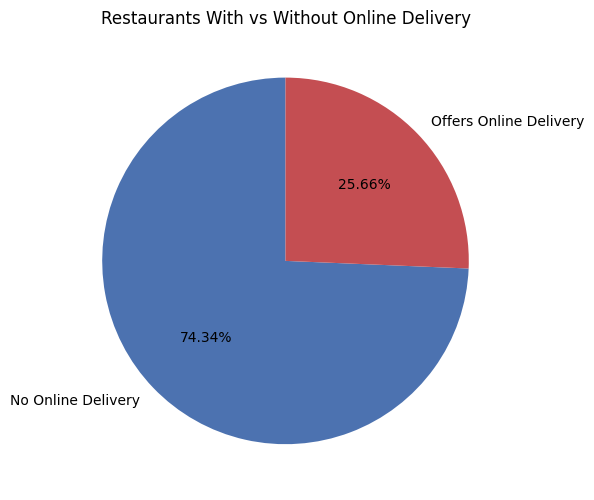

In [27]:
plt.figure(figsize=(6, 6))
plt.pie(
    delivery_summary["Restaurant Count"],
    labels=delivery_summary["Online Delivery"].map({"Yes": "Offers Online Delivery", "No": "No Online Delivery"}),
    autopct="%1.2f%%",
    startangle=90,
    colors=["#4C72B0", "#C44E52"]
)
plt.title("Restaurants With vs Without Online Delivery")
plt.tight_layout()
plt.show()

## 4. Average Rating: With vs Without Online Delivery

Two versions are calculated:

- **All listings:** literal average of `Aggregate rating`, including the zeros.
- **Rated only:** excludes restaurants with rating `0` (the fairer comparison).

In [21]:
avg_all = df.groupby("Has Online delivery")["Aggregate rating"].mean().round(2)

unrated_share = (
    df.groupby("Has Online delivery")["Aggregate rating"]
    .apply(lambda s: (s == 0).mean() * 100)
    .round(2)
)

rated_df = df[df["Aggregate rating"] > 0]
rated_stats = rated_df.groupby("Has Online delivery")["Aggregate rating"].agg(["mean", "median", "count"]).round(2)

rating_comparison = pd.DataFrame({
    "Avg Rating (all listings)": avg_all,
    "Unrated Share (%)": unrated_share,
    "Avg Rating (rated only)": rated_stats["mean"],
    "Median Rating (rated only)": rated_stats["median"],
    "Rated Restaurants": rated_stats["count"]
})
rating_comparison

,Avg Rating (all listings),Unrated Share (%),Avg Rating (rated only),Median Rating (rated only),Rated Restaurants
Has Online delivery,,,,,
No,2.47,28.90,3.47,3.4,5048
Yes,3.25,3.92,3.38,3.4,2355


In [22]:
diff_all = avg_all["Yes"] - avg_all["No"]
diff_rated = rated_stats.loc["Yes", "mean"] - rated_stats.loc["No", "mean"]

print(f"Difference (with - without), all listings: {diff_all:+.2f}")
print(f"Difference (with - without), rated only:  {diff_rated:+.2f}")

Difference (with - without), all listings: +0.78
Difference (with - without), rated only:  -0.09


At first glance, restaurants **with** online delivery look better rated. But
the gap comes mostly from unrated restaurants: a much larger share of
restaurants without delivery are unrated (rating 0), which pulls their average
down. The fair comparison is the rated-only one, shown above.

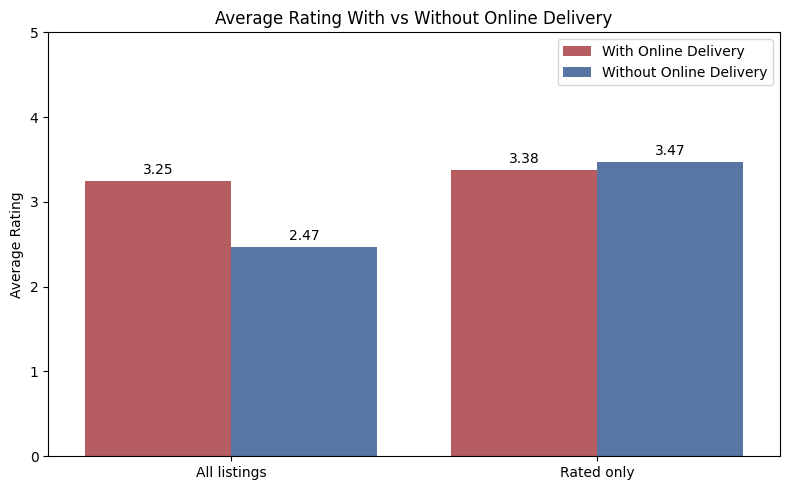

In [23]:
plot_df = pd.DataFrame({
    "Group": ["With Online Delivery", "Without Online Delivery"] * 2,
    "Measure": ["All listings"] * 2 + ["Rated only"] * 2,
    "Average Rating": [
        avg_all["Yes"], avg_all["No"],
        rated_stats.loc["Yes", "mean"], rated_stats.loc["No", "mean"]
    ]
})

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=plot_df, x="Measure", y="Average Rating", hue="Group",
                 palette=["#C44E52", "#4C72B0"])
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)
plt.ylim(0, 5)
plt.title("Average Rating With vs Without Online Delivery")
plt.xlabel("")
plt.ylabel("Average Rating")
plt.legend(title="")
plt.tight_layout()
plt.show()

## 5. Robustness Check: India vs Rest of the World

In [24]:
india = df["Currency"].str.contains("Indian")

print(f"India share of dataset: {india.mean() * 100:.2f}%\n")

print("Online delivery availability (%):")
availability = pd.DataFrame({
    "India (%)": (df[india]["Has Online delivery"].value_counts(normalize=True) * 100).round(2),
    "Outside India (%)": (df[~india]["Has Online delivery"].value_counts(normalize=True) * 100).round(2)
})
display(availability)

print("Average rating, rated restaurants only:")
region_rating = pd.DataFrame({
    "India": rated_df[india.loc[rated_df.index]].groupby("Has Online delivery")["Aggregate rating"].mean().round(2),
    "Outside India": rated_df[~india.loc[rated_df.index]].groupby("Has Online delivery")["Aggregate rating"].mean().round(2),
})
region_counts = pd.DataFrame({
    "India (n)": rated_df[india.loc[rated_df.index]].groupby("Has Online delivery").size(),
    "Outside India (n)": rated_df[~india.loc[rated_df.index]].groupby("Has Online delivery").size(),
})
display(region_rating.join(region_counts))

India share of dataset: 90.59%

Online delivery availability (%):


,India (%),Outside India (%)
Has Online delivery,,
No,71.99,96.89
Yes,28.01,3.11


Average rating, rated restaurants only:


,India,Outside India,India (n),Outside India (n)
Has Online delivery,,,,
No,3.34,4.08,4186,862
Yes,3.37,4.11,2327,28


## 6. Final Results

In [25]:
task4_result = pd.DataFrame({
    "Question": [
        "Restaurants offering online delivery",
        "Percentage offering online delivery",
        "Avg rating WITH delivery (all listings)",
        "Avg rating WITHOUT delivery (all listings)",
        "Avg rating WITH delivery (rated only)",
        "Avg rating WITHOUT delivery (rated only)",
    ],
    "Answer": [
        f"{yes_count:,}",
        f"{yes_pct:.2f}%",
        f"{avg_all['Yes']:.2f}",
        f"{avg_all['No']:.2f}",
        f"{rated_stats.loc['Yes', 'mean']:.2f}",
        f"{rated_stats.loc['No', 'mean']:.2f}",
    ],
})
task4_result

,Question,Answer
0,Restaurants offering online delivery,"2,451"
1,Percentage offering online delivery,25.66%
2,Avg rating WITH delivery (all listings),3.25
3,Avg rating WITHOUT delivery (all listings),2.47
4,Avg rating WITH delivery (rated only),3.38
5,Avg rating WITHOUT delivery (rated only),3.47


## 7. Validation

In [26]:
print("Total restaurants:", len(df))
print("Sum of Yes + No counts:", delivery_counts.sum())
print("Counts match:", len(df) == delivery_counts.sum())
print("Percentages sum to:", round(delivery_pct.sum(), 2))
print("Rated + unrated = total:", len(rated_df) + unrated == len(df))

Total restaurants: 9551
Sum of Yes + No counts: 9551
Counts match: True
Percentages sum to: 100.0
Rated + unrated = total: True


### Business Insights

- **25.66%** of restaurants (**2,451**) offer online delivery, while **74.34%**
  (**7,100**) do not. About three out of four listings have no online delivery.
- **At first glance, delivery looks linked to better ratings:** 3.25 with
  delivery versus 2.47 without (a 0.78 gap).
- **But this gap is misleading.** About **28.90%** of restaurants without
  delivery are unrated (rating 0), compared with only **3.92%** of those with
  delivery. These zeros pull the "without delivery" average down.
- **Among rated restaurants only, the gap disappears and even reverses
  slightly:** 3.38 with delivery versus 3.47 without (a difference of -0.09).
  The median rating is the same for both groups (3.40).
- **The India vs outside-India split confirms this.** Online delivery is
  concentrated in India (28.01% of Indian listings versus only 3.11% outside
  India). Within India, ratings are almost identical with and without delivery
  (3.37 vs 3.34), and outside India the same holds (4.11 vs 4.08), although
  only 28 restaurants outside India offer delivery, so that sample is small.
- **Conclusion:** offering online delivery does not by itself make a
  restaurant better rated. The raw difference mainly reflects unrated
  restaurants and the different mix of countries, not dining quality.
- **Caution:** this shows association, not cause. The data does not tell us
  whether delivery changes ratings or whether the type of restaurant that offers
  delivery is different to begin with.